# Chapter 21 | Worked solutions

*Search, Retrieval, and Grounded Assistants*

Work through all twelve exercises, from lexical scores and context budgets
to evidence support and evaluation design. The examples use fictional office
notices. Exercises 9-12 are optional extensions. The written edition keeps
every explanation and plot; the notebook PDF also includes code and saved
results. The design exercises include illustrative annotations and controlled
checks, not measurements of a trained assistant.

## Setup

Open this notebook inside `transformers-book`. Install `requirements.txt`,
`matplotlib`, and `jupyterlab`, then run all cells in order on CPU. No model
or dataset download is required. The teaching tokenizer counts words;
deployment budgets must use the generator's tokenizer on the whole prompt.
The vector and reranker scores are supplied examples, not learned outputs.

In [1]:
from pathlib import Path
import sys
import math
from datetime import date
import numpy as np
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

for repo_root in (Path.cwd(), *Path.cwd().parents):
    if (repo_root / "examples/ch21_retrieval/model.py").is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError("Open this notebook inside transformers-book.")
from examples.ch21_retrieval.model import (
    tokenize, bm25_scores, dense_scores, rank_passages,
    rerank_candidates, pack_context, literal_evidence_hits, evidence_recall,
)
print("Ready: local scoring, packing and evidence checks")

Ready: local scoring, packing and evidence checks


## 1. Compare two query words

The first word appears in only two of ten passages. Matching that word is
more distinctive than matching one present in eight passages. Document
frequency counts passages containing the word, not all its occurrences.
Substitute the two counts into the positive IDF formula:

$$
\begin{aligned}
\operatorname{IDF}_{2}&=\ln\left(1+\frac{10-2+0.5}{2+0.5}\right)
=\ln(4.4)\approx1.482,
\\
\operatorname{IDF}_{8}&=\ln\left(1+\frac{10-8+0.5}{8+0.5}\right)
=\ln(22/17)\approx0.258.
\end{aligned}
$$

With equal positive frequencies and equal length factors in the candidate,
both IDFs are multiplied by the same positive number. The rarer word
contributes more. If neither word occurs in the candidate, both contributions
are zero regardless of their IDFs.

In [2]:
idf_rare = math.log1p((10 - 2 + .5) / (2 + .5))
idf_common = math.log1p((10 - 8 + .5) / (8 + .5))
assert idf_rare > idf_common > 0
print(f"df=2: {idf_rare:.6f}; df=8: {idf_common:.6f}")

df=2: 1.481605; df=8: 0.257829


## 2. Change the query direction

The query $(0,1)$ reads the second coordinate. P1, P2, and P3 receive scores
0.6, 0.8, and 1.0, so the descending order is P3, P2, P1. For a query $(x,y)$,
subtract the P2 score from the P1 score:

$$
(0.8x+0.6y)-(0.6x+0.8y)=0.2(x-y).
$$

P1 has a strictly higher score exactly when $x>y$. If $x=y$, the scores tie;
the ID tie break still places P1 first, but that ordering is not evidence
of a stronger match. The supplied passage vectors have unit length. The
function computes raw dot products and does not normalize other inputs.

In [3]:
vectors = np.array([[.8,.6],[.6,.8],[0,1]])
scores = dense_scores([0,1], vectors)
np.testing.assert_allclose(scores, [.6,.8,1])
assert rank_passages(("P1","P2","P3"),scores) == ("P3","P2","P1")
print("Scores:",scores,"; order:",rank_passages(("P1","P2","P3"),scores))
for q in ([2,1],[1,1],[1,2]):
    s = dense_scores(q,vectors)
    np.testing.assert_allclose(s[0]-s[1],.2*(q[0]-q[1]),atol=1e-15)
    print("Query",q,"; P1 - P2:",round(s[0]-s[1],3))

Scores: [0.6 0.8 1. ] ; order: ('P3', 'P2', 'P1')
Query [2, 1] ; P1 - P2: 0.2
Query [1, 1] ; P1 - P2: 0.0
Query [1, 2] ; P1 - P2: -0.2


## 3. Fit a short context

Visit P1, P2, P3, P4 in order. The rule checks every passage, including
those after one that does not fit. At budget 11 the trace is:

| Passage | Cost | Before | Decision | After |
|---|---|---|---|---|
| P1 | 9 | 11 | Keep | 2 |
| P2 | 5 | 2 | Skip | 2 |
| P3 | 4 | 2 | Skip | 2 |
| P4 | 2 | 2 | Keep | 0 |

The result is P1, P4. At budget 14, P1 leaves five tokens and P2 uses all
five; P3 and P4 are skipped. The result is P1, P2. Ranking gives each
passage its turn, while its length determines whether it fits at that turn.
This greedy procedure does not optimize the number of passages or the
coverage of the answer. The notebook uses repeated-word texts only
to give each item its prescribed cost.

In [4]:
costs = {"P1":9,"P2":5,"P3":4,"P4":2}
cost_corpus = {pid:" ".join(["word"]*cost) for pid,cost in costs.items()}
for budget,expected in [(11,("P1","P4")),(14,("P1","P2"))]:
    kept = tuple(pid for pid,_ in pack_context(costs,cost_corpus,budget))
    assert kept == expected
    print("Budget",budget,"; kept",kept)

Budget 11 ; kept ('P1', 'P4')
Budget 14 ; kept ('P1', 'P2')


## 4. Count missing evidence

The gold evidence set is P2 and P4, so the denominator stays at two.
In the ranking P3, P4, P1, P2, P4 arrives second and P2 arrives fourth.

| Rank cutoff | Required IDs found | Recall | Any found? | Both found? |
|---|---|---|---|---|
| 1 | None | 0 | No | No |
| 2 | P4 | 0.5 | Yes | No |
| 4 | P4, P2 | 1 | Yes | Yes |

At rank two, a hit-rate check reports success even though half the
required evidence is missing. For this question both passages are needed;
an any-evidence hit is therefore too weak to establish answerability.
If multiple passages were independent alternatives, one could be enough.

In [5]:
ranking = ("P3","P4","P1","P2")
gold = ("P2","P4")
for k,expected in [(1,0),(2,.5),(4,1)]:
    found = set(ranking[:k]) & set(gold)
    recall = evidence_recall(ranking,gold,k)
    assert recall == expected
    print(f"k={k}: recall={recall}; any={bool(found)}; all={found==set(gold)}")
assert evidence_recall(ranking,(),4) is None
print("Empty gold: recall is undefined (None)")

k=1: recall=0.0; any=False; all=False
k=2: recall=0.5; any=True; all=False
k=4: recall=1.0; any=True; all=True
Empty gold: recall is undefined (None)


## 5. Mix before or after multiplying

Keep the candidate $(y_1,y_2)$ fixed. Passage A assigns it probability
$0.8(0.3)=0.24$ and B assigns it $0.2(0.9)=0.18$. RAG-Sequence averages
these two path probabilities with the supplied weights:

$$
0.6(0.24)+0.4(0.18)=0.216.
$$

RAG-Token first averages at each position. The chosen first token has
probability $0.6(0.8)+0.4(0.2)=0.56$. After that same first token, the
chosen second token has probability $0.6(0.3)+0.4(0.9)=0.54$. Their product is

$$
0.56(0.54)=0.3024.
$$

The sequence mixture keeps one passage choice across both positions. The
token mixture permits a different latent passage choice at each position.
Mixing and multiplying therefore need not commute. Neither computation
issues a new search for the second token; both use the original retrieved
set. These are probabilities of the two-token prefix; a complete answer
also includes its end marker. The larger probability here does not
establish better answer quality.

In [6]:
weights = np.array([.6,.4])
conditional = np.array([[.8,.3],[.2,.9]])  # rows: A, B; columns: steps
sequence_prob = weights @ conditional.prod(axis=1)
token_prob = (weights @ conditional).prod()
np.testing.assert_allclose([sequence_prob,token_prob],[.216,.3024])
print(f"Sequence mixture: {sequence_prob:.4f}")
print(f"Token mixture:    {token_prob:.4f}")

Sequence mixture: 0.2160
Token mixture:    0.3024


## 6. Turn off length adjustment

P1 tells a resident where to renew a parking permit. P2 gives the expiry
date. Both notices contain *parking* and *permit* once, so the two notices
are a good test of how BM25 uses passage length. Score the three notices
from Table 20.1 in ID order for `parking permit`. Then change only the
length parameter `b` from its default value of `0.75` to `0`.

In [7]:
from examples.ch21_retrieval.model import bm25_scores, rank_passages

passage_ids = ("P1", "P2", "P3")
passage_texts = (
    "Renew a parking permit at the mobility desk.",
    "A parking permit expires on June 30.",
    "The recycling office opens on Tuesday.",
)
query = "parking permit"

default_scores = bm25_scores(query, passage_texts)
no_length_scores = bm25_scores(query, passage_texts, b=0)

print(f"{'Passage':<8} {'Default':>10} {'b = 0':>10}")
for passage_id, default, no_length in zip(
    passage_ids, default_scores, no_length_scores
):
    print(f"{passage_id:<8} {default:>10.6f} {no_length:>10.6f}")

print("Default order", rank_passages(passage_ids, default_scores))
print("b = 0 order", rank_passages(passage_ids, no_length_scores))

Passage     Default      b = 0
P1         0.888105   0.940007
P2         0.940007   0.940007
P3         0.000000   0.000000
Default order ('P2', 'P1', 'P3')
b = 0 order ('P1', 'P2', 'P3')


The passages have 8, 7, and 6 word tokens, so the collection average is
7. Each query word occurs in two of the three passages and contributes the
same inverse document frequency, $\ln(1.6) \approx 0.470004$. In P1 and P2,
each query word occurs once. With the chapter's default $k_1=1.2$, the
score for either matching passage of length $L$ is therefore

$$
2\ln(1.6)\frac{2.2}{1+1.2(1-b+bL/7)}.
$$

With $b=0.75$, the denominator is about 2.329 for P1 and 2.2 for P2. The
smaller denominator gives the shorter notice, P2, the higher score. P3
contains neither query word and scores zero in both runs.

With $b=0$, both denominators are 2.2 and both scores equal $2\ln(1.6)$.
`rank_passages` orders equal scores by ascending passage ID, so P1 comes
first. The rank after the tie break carries no extra evidence about which
passage best answers the question.

In [8]:
# Check both settings against the hand calculation above.
average_length_score = 2 * np.log(1.6)
long_passage_denominator = 1 + 1.2 * (0.25 + 0.75 * 8 / 7)
long_passage_score = average_length_score * 2.2 / long_passage_denominator
np.testing.assert_allclose(
    default_scores, [long_passage_score, average_length_score, 0]
)
np.testing.assert_allclose(
    no_length_scores, [average_length_score, average_length_score, 0]
)
assert rank_passages(passage_ids, default_scores) == ("P2", "P1", "P3")
assert rank_passages(passage_ids, no_length_scores) == ("P1", "P2", "P3")
assert rank_passages(("P2", "P1"), no_length_scores[[1, 0]]) == (
    "P1", "P2"
)


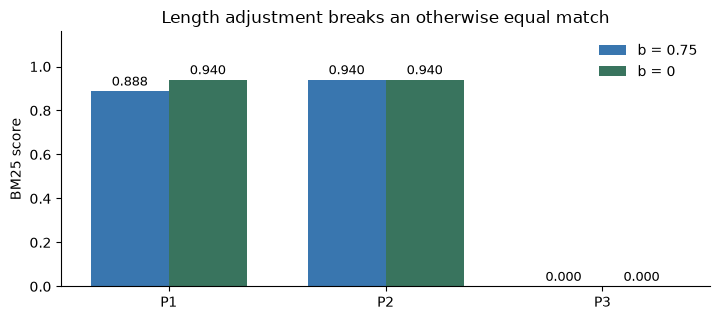

In [9]:
fig,ax = plt.subplots(figsize=(7.3,3.3))
x=np.arange(3)
ax.bar(x-.18,default_scores,.36,label="b = 0.75",color="#3976AF")
ax.bar(x+.18,no_length_scores,.36,label="b = 0",color="#39745E")
ax.set(xticks=x,xticklabels=passage_ids,ylabel="BM25 score",ylim=(0,1.16))
ax.set_title("Length adjustment breaks an otherwise equal match")
ax.legend(frameon=False)
for i in range(3):
    ax.text(i-.18,default_scores[i]+.025,f"{default_scores[i]:.3f}",ha="center",fontsize=9)
    ax.text(i+.18,no_length_scores[i]+.025,f"{no_length_scores[i]:.3f}",ha="center",fontsize=9)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout();plt.show()

The plot isolates passage length: both matching notices contain the same
query terms once, but P2 is shorter. The displayed scores are ranking
quantities, not probabilities of answer correctness.

## 7. Rerank only what was found

For “Where do I renew a parking permit?” the only passage that supplies
the location is P1. Compare a retrieval run that returned P2 and P3 with
one that also returned P1. Keep P2 and P3's scores fixed so we can see
what changes when P1 becomes available.

In [10]:
from examples.ch21_retrieval.model import evidence_recall, rerank_candidates

relevant_ids = ("P1",)
pair_scores = {"P2": 0.2, "P3": 0.7}

candidate_sets = (
    (("P2", "P3"), pair_scores, ("P3", "P2"), 0.0),
    (
        ("P2", "P3", "P1"),
        {**pair_scores, "P1": 0.9},
        ("P1", "P3", "P2"),
        1.0,
    ),
)
for candidates, scores, expected_order, expected_recall in candidate_sets:
    reranked = rerank_candidates(candidates, scores)
    recall = evidence_recall(reranked, relevant_ids, k=1)
    assert reranked == expected_order
    assert recall == expected_recall
    print("Candidates", candidates)
    print("Reranked  ", reranked)
    print("Recall@1  ", recall)
    print()

Candidates ('P2', 'P3')
Reranked   ('P3', 'P2')
Recall@1   0.0

Candidates ('P2', 'P3', 'P1')
Reranked   ('P1', 'P3', 'P2')
Recall@1   1.0



Recall at rank one is the number of required evidence IDs in the first
result divided by the total number of required IDs. Here there is one
required ID, P1.


With **P2 and P3**, P3 comes first because $0.7 > 0.2$. The top result
  contains zero of the one required IDs, giving recall $0/1=0$.

With **P2, P3, and P1**, the order is P1, P3, P2 because
  $0.9 > 0.7 > 0.2$. The top result contains P1, giving recall $1/1=1$.

Retrieval chooses which passages the reranker can consider. Reranking
changes their order using the supplied query–passage scores. When
retrieval includes P1, its score moves it from third to first. When
retrieval omits P1, changing the order of P2 and P3 leaves the evidence
absent.

## 8. Keep the passage and ID together

The answer to “Where can I renew a parking permit?” is in P1.
Begin with the ranking P2, P1, P3 and see whether P1 makes it
into the context. Then put P1 first and repeat the comparison
at the same budget of 14 tokens.

A passage's cost is its number of tokens under the chapter's
teaching tokenizer. It lowercases words, ignores the final
periods, and counts the number `30` as one token. The budget
here covers only passage text. The ID travels with the text
as a separate field.

In [11]:
from examples.ch21_retrieval.model import (
    literal_evidence_hits,
    pack_context,
    tokenize,
)

packing_corpus = {
    "P1": "Renew a parking permit at the mobility desk.",
    "P2": "A parking permit expires on June 30.",
    "P3": "The recycling office opens on Tuesday.",
}
passage_costs = {
    passage_id: len(tokenize(passage))
    for passage_id, passage in packing_corpus.items()
}
assert passage_costs == {"P1": 8, "P2": 7, "P3": 6}

for passage_id, passage in packing_corpus.items():
    words = " ".join(tokenize(passage))
    print(f"{passage_id} ({passage_costs[passage_id]} tokens)  {words}")

P1 (8 tokens)  renew a parking permit at the mobility desk
P2 (7 tokens)  a parking permit expires on june 30
P3 (6 tokens)  the recycling office opens on tuesday


`pack_context` reads the ranking from left to right. It keeps
a whole passage if its cost is at most the remaining budget.
If a passage is too long, it skips that passage and tries
the next one. Each retained pair includes the original
passage ID and the full text from the dictionary.

In [12]:
original_order = ("P2", "P1", "P3")
p1_first_order = ("P1", "P2", "P3")
packing_cases = [
    (original_order, 7, ("P2",), 0, ()),
    (original_order, 14, ("P2", "P3"), 1, ()),
    (p1_first_order, 14, ("P1", "P3"), 0, ("P1",)),
]

for order, budget, expected_ids, left, expected_hits in packing_cases:
    context = pack_context(order, packing_corpus, budget)
    hits = literal_evidence_hits(context, "mobility desk")
    used = sum(passage_costs[passage_id] for passage_id, _ in context)

    expected_context = tuple(
        (passage_id, packing_corpus[passage_id])
        for passage_id in expected_ids
    )
    assert context == expected_context
    assert budget - used == left
    assert hits == expected_hits

    print(f"{' -> '.join(order)} with budget {budget}")
    for passage_id, passage in context:
        print(f"  {passage_id}  {passage}")
    print(f"  Tokens left {budget - used}. Phrase hits {hits}.")

P2 -> P1 -> P3 with budget 7
  P2  A parking permit expires on June 30.
  Tokens left 0. Phrase hits ().
P2 -> P1 -> P3 with budget 14
  P2  A parking permit expires on June 30.
  P3  The recycling office opens on Tuesday.
  Tokens left 1. Phrase hits ().
P1 -> P2 -> P3 with budget 14
  P1  Renew a parking permit at the mobility desk.
  P3  The recycling office opens on Tuesday.
  Tokens left 0. Phrase hits ('P1',).


**P2, P1, P3 with budget 7.** P2 uses all seven tokens.
  Neither P1 nor P3 fits in the zero tokens left. The packed
  context contains only P2, and the phrase has no hits.

**P2, P1, P3 with budget 14.** P2 leaves seven tokens.
  P1 needs eight, so it is skipped. P3 needs six, so it fits
  and leaves one token. The packed context contains P2 and
  P3, and the phrase has no hits.

**P1, P2, P3 with budget 14.** P1 leaves six tokens.
  P2 needs seven, so it is skipped. P3 fits exactly. The
  packed context contains P1 and P3, and the hit is P1.

The same three passages were retrieved in every run. At
budget 14, the first of P1 and P2 to be visited uses enough
of the budget to exclude the other, since their combined
cost is 15. The first two runs lose the renewal location
during packing. Keeping each ID attached to its text lets
us check which passage actually reached the input and what
a citation to that passage would support.

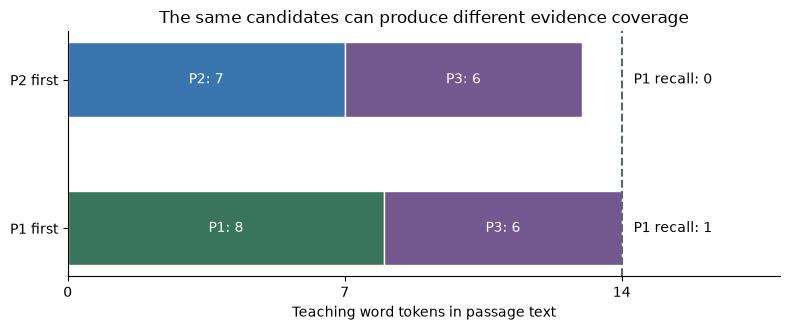

In [13]:
fig,ax = plt.subplots(figsize=(8,3.4))
cases=[(("P2","P1","P3"),14),(("P1","P2","P3"),14)]
colors={"P1":"#39745E","P2":"#3976AF","P3":"#72588F"}
for row,(order,budget) in enumerate(cases):
    context=pack_context(order,packing_corpus,budget)
    left=0
    for pid,_ in context:
        cost=passage_costs[pid]
        ax.barh(row,cost,left=left,color=colors[pid],edgecolor="white",height=.5)
        ax.text(left+cost/2,row,f"{pid}: {cost}",ha="center",va="center",color="white")
        left+=cost
    ids=tuple(pid for pid,_ in context)
    recall=evidence_recall(ids,("P1",),len(ids))
    ax.text(14.3,row,f"P1 recall: {recall:.0f}",va="center")
ax.axvline(14,color="#596772",linestyle="--")
ax.set(yticks=[0,1],yticklabels=["P2 first","P1 first"],xlim=(0,18),
       xticks=[0,7,14],xlabel="Teaching word tokens in passage text")
ax.invert_yaxis();ax.spines[["top","right"]].set_visible(False)
ax.set_title("The same candidates can produce different evidence coverage")
fig.tight_layout();plt.show()

Both bars satisfy the budget of 14. The dashed line marks the budget,
and the first bar leaves one token unused. Retrieval found P1 in both
cases; only visiting P1 first preserves it in the final context. The
reported recall uses the packed IDs, with the same one-passage gold set.

## 9. Probe a literal match (optional)

The claim we want to check is “Express renewals are available.”
Search the two notices for the shorter phrase `express renewals`.
The function lowercases both the phrase and the passage text,
then checks whether the phrase's tokens occur together in order
within each passage. The rest of the sentence does not enter
that check.

In [14]:
from examples.ch21_retrieval.model import literal_evidence_hits

renewal_context = (
    ("P4", "Express renewals are available"),
    ("P5", "Express renewals are no longer available"),
)
renewal_hits = literal_evidence_hits(
    renewal_context, "express renewals"
)
assert renewal_hits == ("P4", "P5")

for passage_id, passage in renewal_context:
    print(f"{passage_id}  {passage}")
print(f"Phrase hits {renewal_hits}")

P4  Express renewals are available
P5  Express renewals are no longer available
Phrase hits ('P4', 'P5')


Both notices begin with the consecutive tokens `express` and
`renewals`, so both IDs match. P4 states that express renewals
are available. In P5, “no longer” changes the claim about
current availability. P5 contradicts the positive claim.

A phrase hit can help locate the passage to read. To judge
support for the positive claim, read what each passage says
about the service, including any negation. A notice that says
“You can renew through the express service” could support the
same claim even though this phrase search would miss it.

## 10. Choose a passage boundary (optional)

Consider: "Renew a parking permit online. If your address changed this
month, renew in person at the mobility desk." A resident who moved this
month needs the exception. Answering with the general online rule would
misapply the notice even though those words really occur in the source.

Compare two indexes. One stores the sentences separately under distinct
IDs with their parent document and offsets; the other stores the whole
notice. Keep P2 and P3 as distractors. Splitting can return the general
rule without its exception. Keeping the notice together preserves the
relationship when the entire passage fits, but the longer passage may
be excluded by a small budget. Neither boundary choice always wins.

Before running retrieval, label supporting spans in the original document.
Use those spans as the scoring units in both indexes. Counting passage IDs
would change the denominator when two passages become one. Include questions
about the ordinary route, a recent move, and both routes together; add
paraphrases such as "I relocated this month. How do I extend my parking
authorization?" Keep queries, retriever, rank cutoff, packing policy, token
budget, and generator settings fixed, rebuilding each index as needed.

Record required-span coverage at retrieval and after packing. For a question
asking both routes, require both spans. Repeat at a larger budget to separate
boundary effects from space limits. Score the answer independently: the
recent-move case must direct the resident to the mobility desk and preserve
the condition; the both-routes case needs the ordinary rule as well. Check
citations against the actual supplied text. A control that supplies both
sentences directly tests whether the generator can use evidence when search
and packing have already succeeded.

The notebook fixture records which annotated spans are visible.
It demonstrates the scoring unit; it does not run a retriever or generator.

In [15]:
span_cases = {
    "split, general rule only": {"general"},
    "split, both sentences": {"general","exception"},
    "joint passage retained": {"general","exception"},
}
required_spans={"general","exception"}
for name,visible in span_cases.items():
    coverage=len(visible & required_spans)/len(required_spans)
    print(f"{name}: required-span coverage={coverage:.1f}")
assert "exception" not in span_cases["split, general rule only"]

split, general rule only: required-span coverage=0.5
split, both sentences: required-span coverage=1.0
joint passage retained: required-span coverage=1.0


## 11. Design an abstention test (optional)

Use the three notices as the entire collection. An abstention explicitly
says that this collection supplies insufficient evidence for the question.

| Question | Expected behavior |
|---|---|
| When does a parking permit expire? | Answer June 30 and cite P2. |
| Is there a grace period after expiry? | Say the notices do not specify one. |
| Who won the district chess tournament? | Say the notices do not provide this information. |

The grace-period question shares vocabulary with P2. Quoting its expiry date
does not answer the question. Saying "There is no grace period" would also
go beyond the evidence: absence from the collection leaves its status
unknown. A supported fact can explain an abstention, but cannot replace it.

For the answerable case, score the correct date, a supporting citation to
P2 from the actual prompt, and absence of invented additions separately.
Count a refusal as a missed answer in the end-to-end task. For each
unanswerable case, credit an explicit statement of insufficient evidence
without an invented answer. Changing the subject earns no credit.

For a larger test, report grounded-answer rate and false-abstention rate
on answerable questions. Report appropriate abstentions and unsupported
answers separately on related and unrelated unanswerable questions. Use
the number of questions in each group as its denominator and show counts.
In this three-case fixture, always abstaining passes two cases overall
but answers zero of the one answerable questions.

Log retrieved and packed IDs. If P2 never reached the prompt, refusing
the expiry question can be appropriate for the generator while the full
system still failed to answer an answerable question. Supplying P2 directly
is a useful control. Empty gold evidence yields undefined retrieval recall;
it should not silently become zero. Here unanswerability was established
by reading all three notices, not inferred from missing labels.

The notebook evaluates an explicitly supplied always-abstain fixture.
It is a rubric sanity check, not an observed model benchmark.

In [16]:
answerable = np.array([True,False,False])
abstained = np.ones(3,dtype=bool)
appropriate = (~answerable) & abstained
false_abstention = answerable & abstained
assert appropriate.sum()==2 and false_abstention.sum()==1
print("Always-abstain fixture:")
print("Appropriate abstentions among unanswerable: 2/2")
print("False abstentions among answerable: 1/1")
print("Grounded answers among answerable: 0/1")

Always-abstain fixture:
Appropriate abstentions among unanswerable: 2/2
False abstentions among answerable: 1/1
Grounded answers among answerable: 0/1


## 12. Audit two versions (optional)

Keep P1 as the current notice directing renewals to the mobility desk.
Add P1-old directing them to the records counter. Both belong to the same
office and policy. A query containing "renew a parking permit" matches
both; the applicable date determines which text governs the answer.

Record stable version-specific passage IDs, parent document and offsets,
issuing office or jurisdiction, version identifier, source location,
effective start and end dates, and explicit supersession links. Keep
publication, upload, and effective dates distinct. A later upload need
not be the currently applicable rule. Preserve old versions so a citation
remains traceable and historical questions can be answered.

For a fictional test, let P1-old apply from January 1 through March 31,
2026, and P1 from April 1 onward. On April 15 the expected location is
mobility desk with P1; on March 15 it is records counter with P1-old.
Define the clock for undated questions, for example April 15, and save
the collection snapshot. Add paraphrases and queries sharing the exact
renewal words. Label the applicable ID and location before running.

Compare lexical-only retrieval with a version-aware run under the same
rank cutoff and budget. One controlled policy filters by office and
effective interval before ranking eligible notices. These two texts both
have eight teaching tokens and contain each query term once, so their
BM25 scores tie. P1 winning the ID tie break does not demonstrate use of
dates. Historical queries expose that shortcut.

Record applicable-ID recall among candidates, survival after packing,
answer location, citation support, and temporal applicability separately.
A mobility-desk answer citing P1-old has the right current location but
an unsupported citation. A records-counter answer citing P1-old may quote
its source faithfully while using the wrong version for a current question.
If both notices are shown, the answer must resolve their dates rather than
present both desks as current choices. Report current and historical
results separately. If authority or effective dates leave a genuine
conflict, report the uncertainty; choosing the newest timestamp is not
a resolution rule.

The notebook check uses half-open intervals: the start is included and the
end is excluded. An end of April 1 therefore means validity through
March 31. The fixture verifies applicability labels, not model behavior.

In [17]:
versions = {
    "P1-old": (date(2026,1,1),date(2026,4,1)),
    "P1": (date(2026,4,1),None),
}
def applicable(on):
    return tuple(pid for pid,(start,end) in versions.items()
                 if start <= on and (end is None or on < end))
for on,expected in [(date(2026,3,15),("P1-old",)),
                    (date(2026,4,1),("P1",)),
                    (date(2026,4,15),("P1",))]:
    assert applicable(on)==expected
    print(on.isoformat(),applicable(on))
version_texts=("Renew a parking permit at the mobility desk.",
               "Renew a parking permit at the records counter.")
version_scores=bm25_scores("renew a parking permit",version_texts)
np.testing.assert_allclose(version_scores[0],version_scores[1])
print("Lexical scores tie:",np.round(version_scores,6))

2026-03-15 ('P1-old',)
2026-04-01 ('P1',)
2026-04-15 ('P1',)
Lexical scores tie: [0.729286 0.729286]
